In [1]:
config_sir = {
    "prior":
        {
        "gamma_range": [0.05, 0.5],
        "beta_range": [0.5, 5.0],
        },
    "simulator":
        {
        "S": [1500, 2000], # int, tuple, number of Susceptible individuals or bounds for following uniform distribution
        "I": [150, 200], # int, tuple, number of Infectious individuals or bounds for following uniform distribution
        "R": [0, 50], # int, tuple, number of Recovered individuals or bounds for following uniform distribution
        "T": [100, 120],  # int, tuple, simulation duration in days or bounds for following uniform distribution
        },
    "summary": 
        {
        "type": "handmade",
        "input_dim": 3,
        "hidden_dim": 32,
        "num_layers": 2,
        "output_dim": 5,
        "dropout": 0.1,
        },
    "logger":
        {
        "name": "SIR",
        "level": "DEBUG",
        "log_file_path": "logs/sir.log",
        }
}


sfmpe_config = {'device': 'auto', 
 'flow': {
     'init_dist': 'normal', 
     'velocity_model': {
         'type': 'simple', 
         'params': {
             'hidden_dim': 64, 
             'num_layers': 3
            }
        }, 
     'path': {
         'type': 'affine'
        }
     }, 
     'optimizer': {
        'type': 'Adam', 
        'params': {
            'task': {
                'summary': {
                    'lr': 0.0001
                    }
                }, 
            'flow_model': {
                'lr': 0.0001
                }
            }
        }, 
     'loss': 'MSELoss', 
     'proposal': {
        'method': 'Truncated', 
        'n_steps': 8, 
        'params': {
            'quantile': 0.1
            }
        }, 
        'initial': {
            'theta_0': [1.2621, 0.4558]
            }, 
        'logger': {
            'name': 'SIR', 
            'level': 'INFO', 
            'log_to_console': True, 
            'log_to_file': True, 
            'log_file_path': './logs/sir.log'
            }, 'run_sequential': {
                'num_rounds': 3, 
                'sims_per_round': 1000, 
                'sims_per_sample': 1, 
                'clean_sampling': True, 
                'upd_x': False, 
                'training': {'epochs': 1000, 'show_every': 100, 'batch_size': 1000, 'shuffle': True, 'num_workers': 0, 'path': './models/sir.pth'}}}


In [2]:
from sfmpe.inference.SFMPE import SFMPE
from sfmpe.tasks.SIR import SIRTask
import torch

device = 'cuda' if torch.cuda.is_available() else 'cpu'
sir_task = SIRTask(config_sir, device)

pipeline = SFMPE(sir_task, config_path="configs/sfmpe_benchmark_sir.yaml")
pipeline.run()

2026-10-18 16:31:22,296 - SIR - INFO - Starting SIRTask task
2026-10-18 16:31:23,076 - SIR - INFO - Initialized flow model
2026-10-18 16:31:24,866 - SIR - INFO - Task: SIRTask
2026-10-18 16:31:24,867 - SIR - INFO - Estimator: FlowMatchingEstimator
2026-10-18 16:31:24,869 - SIR - INFO - Starting sequential training with 3 rounds
2026-10-18 16:31:24,870 - SIR - INFO - Simulations per round: 1000
2026-10-18 16:31:24,871 - SIR - INFO - Training kwargs: {'epochs': 1000, 'show_every': 100, 'batch_size': 1000, 'shuffle': True, 'num_workers': 0, 'path': './models/sir.pth'}
2026-10-18 16:31:24,872 - SIR - INFO - --- Round 0/3 ---
2026-10-18 16:31:24,873 - SIR - INFO - Starting round 0 with 1000 simulations
2026-10-18 16:31:24,926 - SIR - INFO - Round 0 completed - stored 1000 simulations
2026-10-18 16:31:24,929 - SIR - INFO - Training estimator on 1000 samples from rounds: [0]
2026-10-18 16:31:27,704 - SIR - INFO - Epoch 100: train loss 0.491270, validation loss 0.667008
2026-10-18 16:31:30,408

2026-10-18 16:38:51,102 - SIR - INFO - Building posterior...


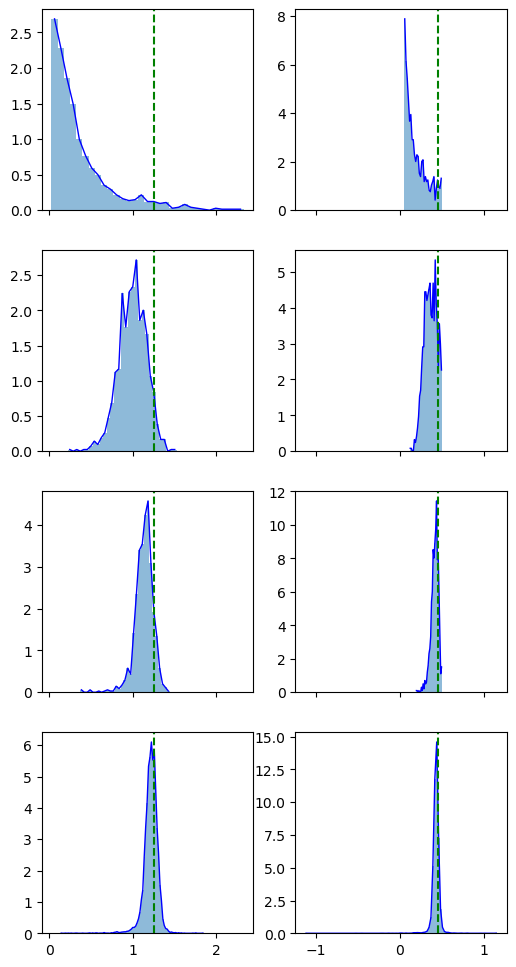

In [6]:
from sfmpe.utils.plotting import dist_plot

sim_store = pipeline.manager.store
posterior = pipeline.manager.build_posterior()

dist_plot(
                sim_store.theta[0].detach().cpu(), 
                sim_store.theta[1].detach().cpu(),
                sim_store.theta[2].detach().cpu(),  
                posterior.sample((10000,)).detach().cpu(),
                # manager.clean_sample((1000, )),
                true_param=pipeline.proposal_params.theta_0.detach().cpu())

In [4]:
config_sv = {
    "prior":
        {
        "mu_loc": 0.0,
        "mu_scale": 0.2,
        "phi_alpha": 20.0,
        "phi_beta": 1.5,
        "sigma_ig_shape": 2.5,
        "sigma_ig_scale": 0.025,
        "m_loc": -1.5,
        "m_scale": 1.0,
        },
    "simulator":
        {
        "T": [200, 250],
        "v0": [-5, 5],
        },
    "summary": 
        {
        "type": "lstm",
        "input_dim": 1,
        "hidden_dim": 32,
        "num_layers": 3,
        "output_dim": 10,
        "dropout": 0.1,
        },
    "logger":
        {
        "name": "StochVol",
        "level": "DEBUG",
        "log_file_path": "logs/stoch_vol.log",
        }
}

from sfmpe.inference.SFMPE import SFMPE
from sfmpe.tasks.StochVol import StochVolTask
import torch

device = 'cuda' if torch.cuda.is_available() else 'cpu'
sv_task = StochVolTask(config_sv, device)

pipeline_sv = SFMPE(sv_task, config_path="configs/sfmpe_benchmark_stochvol.yaml")
# pipeline_sv.run()

2026-10-18 16:38:42,264 - StochVol - INFO - Starting StochVolTask task
2026-10-18 16:38:42,270 - StochVol - INFO - Initialized flow model
2026-10-18 16:38:42,335 - StochVol - INFO - Task: StochVolTask
2026-10-18 16:38:42,337 - StochVol - INFO - Estimator: FlowMatchingEstimator


In [5]:
from sfmpe.utils.plotting import dist_plot

sim_store_sv = pipeline_sv.manager.store
posterior_sv = pipeline_sv.manager.build_posterior()

dist_plot(
                sim_store_sv.theta[0].detach().cpu(), 
                sim_store_sv.theta[1].detach().cpu(),
                sim_store_sv.theta[2].detach().cpu(),  
                posterior_sv.sample((10000,)).detach().cpu(),
                # manager.clean_sample((1000, )),
                true_param=pipeline_sv.proposal_params.theta_0.detach().cpu())

2026-10-18 16:38:42,395 - StochVol - INFO - Building posterior...


IndexError: list index out of range